# FL-SEC-001.5 — Comparative analysis of HE vs SecAgg vs SMPC

*Epic EPIC-001 · story fl_sec_001 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Compare plaintext, CKKS, BFV, SecAgg (with/without dropout) and SMPC on accuracy, time, communication and aggregation error across seeds.

## 2. Scientific background
See tasks 1.1–1.4.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does any mechanism change accuracy?
- **RQ2.** What are the training-time and communication overheads?

## 4. Hypotheses
- **H1.** Accuracy loss < 1 pp for all mechanisms.
- **H2.** Overheads differ by orders of magnitude between mechanisms.

## 5. Mathematical formulation
overhead% = 100·(t_secure − t_plain)/t_plain; accuracy loss (pp) = 100·(acc_plain − acc_secure).

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_sec_001"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_sec_001


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "P": 1442,
 "n": 10,
 "parties": [
  2,
  3,
  5
 ],
 "clients": [
  5,
  10,
  20
 ]
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`fl.py`, `crypto/*`, `monitoring.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.privacy.secure_aggregation import SecureAggregationProtocol, SecAggAbort
n, P = 10, 64; r = np.random.default_rng(SEED); D = r.normal(0, .1, (n, P)); W = r.integers(5, 50, n).astype(float)
pr = SecureAggregationProtocol(n, P)
out, w = pr.run({i: D[i] for i in range(n)}, {i: W[i] for i in range(n)}, drop_before_unmask={2, 3})
print("dropout (2 clients after masking) -> max error vs plaintext:", float(np.abs(out - (W / W.sum()) @ D).max())); assert np.abs(out - (W / W.sum()) @ D).max() < 1e-6
try:
    SecureAggregationProtocol(n, P).run({i: D[i] for i in range(n)}, {i: W[i] for i in range(n)}, drop_before_masking=set(range(7)))
except SecAggAbort as e: print("abort below threshold:", e)

dropout (2 clients after masking) -> max error vs plaintext: 1.886341499668376e-09
abort below threshold: client 0: only 3 shares available, need 7


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-SEC-001.5` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_1_5_comparison_runs.csv')

,config,seed,acc,f1,auc,loss,train_wall_s,agg_time_s,comm_mb,up_mb,rss_peak_mb,max_agg_err,train_overhead_pct,comm_overhead_pct,acc_loss_pp
0,plaintext,0,0.8119,0.7559,0.8885,0.4205,2.1527,0.0028,1.5770,0.7885,979.5781,0.0,0.0000,0.0000,0.0000
1,plaintext,1,0.8108,0.7519,0.8881,0.4215,2.1037,0.0031,1.5770,0.7885,979.5781,0.0,0.0000,0.0000,0.0000
2,plaintext,2,0.8083,0.7551,0.8879,0.4198,2.2011,0.0028,1.5770,0.7885,979.5781,0.0,0.0000,0.0000,0.0000
3,he_ckks,0,0.8119,0.7559,0.8885,0.4205,5.0412,2.2596,48.1887,47.4002,979.6172,0.0,134.1747,5911.4586,0.0000
4,he_ckks,1,0.8108,0.7519,0.8881,0.4215,4.0304,1.6746,48.2139,47.4254,979.6406,0.0,91.5833,5914.6565,0.0000
5,he_ckks,2,0.8083,0.7551,0.8879,0.4198,4.3710,1.8501,48.1867,47.3982,979.6406,0.0,98.5835,5911.1962,0.0000
6,he_bfv,0,0.8117,0.7556,0.8885,0.4205,3.4810,1.2779,62.6520,61.8635,979.6406,0.0,61.7010,7745.7366,0.0278
7,he_bfv,1,0.8111,0.7524,0.8881,0.4216,4.6363,1.8331,62.6501,61.8616,979.6406,0.0,120.3836,7745.5056,-0.0278
8,he_bfv,2,0.8083,0.7551,0.8879,0.4198,3.7658,1.3818,62.6497,61.8612,979.6406,0.0,71.0876,7745.4475,0.0000
9,secagg,0,0.8119,0.7559,0.8885,0.4205,2.8199,0.4242,2.9881,1.9009,979.5938,0.0,30.9915,141.0740,0.0000


## 12. Metrics collection
Metric definitions: MEASURED means and 95% CIs over seeds; overhead formulas above.

In [8]:
show_csv('task_1_5_comparison_summary.csv')

,config,acc,acc_ci,f1,f1_ci,train_wall_s,train_wall_s_ci,agg_time_s,agg_time_s_ci,up_mb,up_mb_ci,train_overhead_pct,train_overhead_pct_ci,comm_overhead_pct,comm_overhead_pct_ci,acc_loss_pp,acc_loss_pp_ci,max_agg_err,max_agg_err_ci
0,plaintext,0.8104,"[0.806, 0.815]",0.7543,"[0.749, 0.76]",2.1525,"[2.03, 2.27]",0.0029,"[0.00254, 0.00325]",0.7885,"[0.788, 0.788]",0.0000,"[0, 0]",0.0000,"[0, 0]",0.0000,"[0, 0]",0.0,"[0, 0]"
1,he_ckks,0.8104,"[0.806, 0.815]",0.7543,"[0.749, 0.76]",4.4809,"[3.2, 5.76]",1.9281,"[1.18, 2.67]",47.4079,"[47.4, 47.4]",108.1138,"[51.4, 165]",5912.4371,"[5.91e+03, 5.92e+03]",0.0000,"[0, 0]",0.0,"[2.3e-08, 4.6e-08]"
2,he_bfv,0.8104,"[0.806, 0.815]",0.7544,"[0.75, 0.759]",3.9610,"[2.47, 5.46]",1.4976,"[0.764, 2.23]",61.8621,"[61.9, 61.9]",84.3907,"[6.09, 163]",7745.5632,"[7.75e+03, 7.75e+03]",0.0000,"[-0.069, 0.069]",0.0,"[2.73e-06, 4.32e-06]"
3,secagg,0.8104,"[0.806, 0.815]",0.7543,"[0.749, 0.76]",2.8820,"[2.63, 3.14]",0.4388,"[0.398, 0.479]",1.9009,"[1.9, 1.9]",33.8723,"[27.2, 40.6]",141.0740,"[141, 141]",0.0000,"[0, 0]",0.0,"[-1.36e-09, 5.71e-09]"
4,secagg_10pct_dropout,0.8110,"[0.805, 0.817]",0.7556,"[0.751, 0.76]",2.7561,"[2.45, 3.07]",0.4200,"[0.363, 0.477]",1.7333,"[1.73, 1.73]",28.0219,"[17.4, 38.6]",119.8258,"[120, 120]",-0.0648,"[-0.773, 0.643]",0.0,"[0, 0]"
5,smpc_3party,0.8104,"[0.806, 0.815]",0.7543,"[0.749, 0.76]",4.7829,"[3.64, 5.92]",2.4612,"[1.6, 3.32]",4.7310,"[4.73, 4.73]",121.9874,"[79.1, 165]",500.0000,"[500, 500]",0.0000,"[0, 0]",0.0,"[2.89e-07, 3.89e-07]"


## 13. Statistical analysis
Bootstrap/t CIs over seeds (unit of replication = seed).

In [9]:
d = pd.read_csv(RES / 'task_1_5_comparison_summary.csv'); display(d[['config','acc','acc_ci','train_overhead_pct','comm_overhead_pct','acc_loss_pp']])

,config,acc,acc_ci,train_overhead_pct,comm_overhead_pct,acc_loss_pp
0,plaintext,0.810370,"[0.806, 0.815]",0.000000,0.000000,0.000000
1,he_ckks,0.810370,"[0.806, 0.815]",108.113848,5912.437107,0.000000
2,he_bfv,0.810370,"[0.806, 0.815]",84.390746,7745.563216,0.000000
3,secagg,0.810370,"[0.806, 0.815]",33.872342,141.074020,0.000000
4,secagg_10pct_dropout,0.811019,"[0.805, 0.817]",28.021901,119.825835,-0.064815
5,smpc_3party,0.810370,"[0.806, 0.815]",121.987409,500.000000,0.000000


## 14. Visualizations

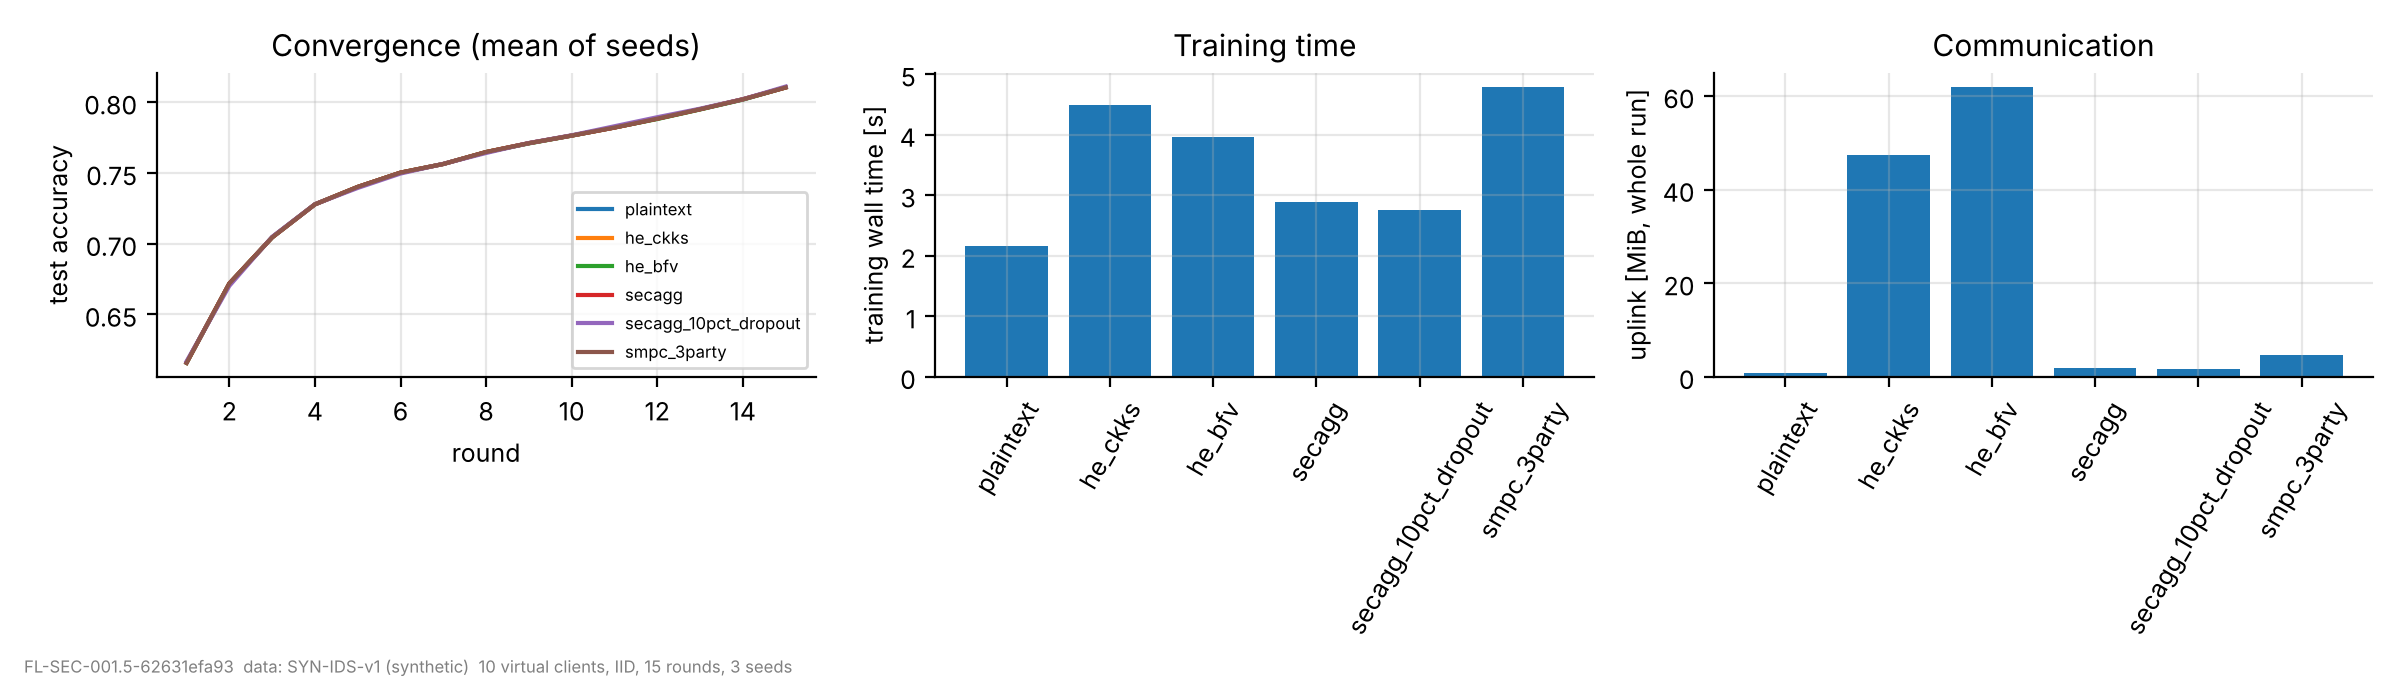

In [10]:
show_fig('task_1_5_comparison.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Accuracy is unchanged by all mechanisms; cost differs strongly (printed).

In [11]:
d = pd.read_csv(RES / 'task_1_5_comparison_summary.csv'); print(d[['config','train_overhead_pct','comm_overhead_pct','acc_loss_pp']].round(2).to_string(index=False))

              config  train_overhead_pct  comm_overhead_pct  acc_loss_pp
           plaintext                0.00               0.00         0.00
             he_ckks              108.11            5912.44         0.00
              he_bfv               84.39            7745.56         0.00
              secagg               33.87             141.07         0.00
secagg_10pct_dropout               28.02             119.83        -0.06
         smpc_3party              121.99             500.00         0.00


## 16. Limitations
- Small seed count; timing depends on the 2-core machine.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Mechanism choice is a cost/trust trade-off, not an accuracy trade-off, in this simulation.

**Jira acceptance:** see `docs/fl_sec_001/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`bonawitz2017`, `cheon2017`, `damgard2012`, `kairouz2021` — details in `docs/fl_sec_001/references.md`.